## Praktikum 3
##### PyTorch

In diesem Praktikum betrachten wir PyTorch und seine Architektur. Wir nutzen dies, um einige Convoluted Neural Networks (CNNs) zu trainieren.

<div style="padding: 10px; border-left: 5px solid #B777FA; background-color: #5C18FA; border-radius: 4px">
  🐍 Bitte nutzen Sie die virtuelle Umgebung: <b>DLACV_2526_PyTorch</b>
</div>

In [91]:
# imports
import numpy as np
import matplotlib.pyplot as plt

from torch.nn import Sequential, Linear, Conv2d, MaxPool2d, Dropout, Flatten, Softmax, ReLU, CrossEntropyLoss
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from torch.optim import RMSprop, Adam
import torch
from torchvision.transforms import PILToTensor, v2, ToTensor
from torchvision.datasets import MNIST

import tqdm
from collections import defaultdict
from enum import Enum
import cv2
import os

import utils.torch_utils as tUtils
from utils.draw_widget import DrawWidget

In [92]:
# Definieren der Ausführungsmodi
class Mode(Enum):
    TRAIN = 0
    TEST = 1

# Ausführungsmodus
MODE = Mode.TRAIN

# Haben Wirkung auf Genauigkeit und Performance
BATCH_SIZE = 256  # Reduzieren Sie diesen Wert, sollte der Code crashen
EPOCHS = 20
AUGMENT_IMAGES = True  # Erhöht die Genauigkeit stark, erhöht aber auch die Trainingszeit innerhalb eines Notebooks

# Diese Werte sollen nicht geändert werden
NUM_WORKERS = 0  # Muss 0 im Notebook bleiben, da es sonst crasht
WIN_NAME = "Zeichnen Sie eine Ziffer [0-9]"
MODEL_SAVE_PATH = "./data/models/mnist-numbers.best-torch.pt"
N_CLASSES = 10  # 0 - 9

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 1.1:</b><br>
  • Setzen Sie das Ausführungsdevice so, dass PyTorch über CUDA trainiert, falls es verfügbar ist. Ansonsten soll die CPU verwendet werden.<br>
  • Geben Sie aus, welches Ausführungsdevice Ihr System verwendet.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Falls Sie CUDA verwenden, das Netzwerk aber beim Trainieren Fehler wirft (und Sie Torch richtig installiert haben), können Sie alternativ über die CPU trainieren.<br>
Das ist nur deutlich langsamer.
</div>

In [93]:
# Ausführungs-Device ändern
device = "cuda"

print("Ausführungs-Device: " + str(device))

Ausführungs-Device: cuda


<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 1.2:</b><br>
  • Fügen Sie zum <code>v2.Compose</code> mindestens 2 unterschiedliche weitere Data-Augmentations hinzu.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Vermeiden Sie das Spiegeln, um Zahlen wie 2 und 5 nicht unnötig zu vermischen. <i>(Das Datenset ist nicht sehr groß.)</i>
</div>

In [94]:
transform = v2.Compose([
    # Wandle Daten in Tensoren um
    ToTensor(),  # Diese Zeile darf nicht entfernt werden

    # Data-Augmentations hinzufügen
    v2.GaussianBlur(7,1),
    v2.RandomAffine(0.1,(0.1,0.1),(0.9,1.1),4),

    # Nachverarbeitung: Normalisierung mit MNIST-Werten
    v2.Normalize((0.1307,),(0.3081,)) # Diese Zeile darf nicht entfernt werden
])

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 1.3:</b><br>
  • Erstellen Sie ein (sequentielles) CNN-Model, indem Sie die Funktion <code>createModel</code> implementieren.<br>
  • Nutzen Sie mindestens 4 Convolutional-Layer zur Feature-Extraktion und 2 Max-Pool-Layer zum Downsampling.<br>
  • Flatten Sie das Model, um (mindestens 1) Linear-Layer zu nutzen.<br>
  • Nutzen Sie die Funktion <code>createModel</code>, um das Modell anzulegen und mappen Sie es auf das Ausgabedevice.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis 1:</b></i> Sie sollten kein <code>Softmax</code>-Layer am Ende einfügen. Das wird automatisch von <code>CrossEntropyLoss</code> gemacht. <a href="https://stackoverflow.com/questions/55675345/should-i-use-softmax-as-output-when-using-cross-entropy-loss-in-pytorch">Mehr Informationen</a><br>
💡 <i><b>Hinweis 2:</b></i> Nutzen Sie die Konstante <code>N_CLASSES</code>, um die Ausgabegröße des letzten Layers zu definieren.
</div>

In [95]:
def createModel():
    model = Sequential(
        Conv2d(1,32,3,padding=1),ReLU(),Conv2d(32,32,3,padding=1),ReLU(),MaxPool2d(2),Conv2d(32,64,3,padding=1),ReLU(),Conv2d(64,64,3,padding=1),ReLU(),MaxPool2d(2),Flatten(),Linear(3136,N_CLASSES)
    )
    return model

# Model anlegen und auf CUDA (falls möglich) setzen
model = createModel().to(device)

# Model ausgeben
print(model)
print(model(torch.zeros(1, 1, 28, 28, device=device)).shape)  # should be torch.Size([1, 10])


Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU()
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU()
  (7): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU()
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Flatten(start_dim=1, end_dim=-1)
  (11): Linear(in_features=3136, out_features=10, bias=True)
)
torch.Size([1, 10])


<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 1.4:</b><br>
  • Schauen Sie sich in Ruhe die Datei <code>utils/torch_utils.py</code> an. Es ist in diesem Notebook als <code>tUtils</code> importiert.<br>
  • Trainieren Sie das Modell, indem Sie die entsprechende Methode verwenden. Achten Sie darauf, auf dem richtigen Ausgabedevice zu trainieren.<br>
  • Speichern Sie die trainierten Modellgewichte unter dem <code>MODEL_SAVE_PATH</code> ab.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis 1:</b></i> Achten Sie darauf, dass die Konstante <code>MODE</code> den richtigen Wert hat.<br>
💡 <i><b>Hinweis 2:</b></i> Aufgrund der Größe des Datensets kann es sein, dass das Modell (falls Sie CUDA verwenden) teilweise auf der GPU und größtenteils auf der CPU trainiert wird<br>
Das liegt an dem GPU-Overhead, den man bei so einem kleinen Datenset vermeiden möchte.<br>
💡 <i><b>Hinweis 3:</b></i> Achten Sie darauf, dass der Ordner <code>data/models</code> existiert, bevor Sie anfangen zu trainieren.<br>
💡 <i><b>Hinweis 4:</b></i> Falls das Training länger dauert als üblich, starten Sie Visual Studio Code neu. Manchmal bleiben Residuen aus anderen Notebooks übrig.<br>
💡 <i><b>Hinweis 5:</b></i> Speichern Sie nur die Gewichte des Modells, nicht das Modell selbst.
</div>

In [96]:
if MODE == Mode.TRAIN:
    # Datenset downloaden falls noch nicht geschehen
    train_dataset = MNIST('./data', train=True, download=True, transform=transform)
    val_dataset = MNIST('./data', train=False, download=True, transform=transform)

    if not AUGMENT_IMAGES:
        # Daten vorbereiten
        train_inputs = torch.as_tensor(train_dataset.data, device=device).unsqueeze(1) / 255.0
        train_labels = F.one_hot(torch.as_tensor(train_dataset.targets, device=device, dtype=torch.int64), N_CLASSES).float()

        val_inputs = torch.as_tensor(val_dataset.data, device=device).unsqueeze(1) / 255.0
        val_labels = F.one_hot(torch.as_tensor(val_dataset.targets, device=device, dtype=torch.int64), N_CLASSES).float()

        train_dataset = TensorDataset(train_inputs, train_labels)
        val_dataset = TensorDataset(val_inputs, val_labels)

    # Data-Loaders erstellen
    train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
    val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)

In [97]:
if MODE == Mode.TRAIN:
    # Optimizer und Loss erstellen
    optimizer = Adam(model.parameters(), lr=0.001)
    criterion = CrossEntropyLoss()

    # Modell trainieren
    history = tUtils.train(model, EPOCHS, optimizer, criterion, train_loader, val_loader, device=device)

    # Modell speichern
    torch.save(model.state_dict(),MODEL_SAVE_PATH)
    print(f"Modell abgespeichert unter '{MODEL_SAVE_PATH}'.")

Epoch 19: 100%|██████████| 235/235 [01:02<00:00,  3.74it/s, loss=0.0247, accuracy=0.992, loss_val=0.0284, accuracy_val=0.991]

Modell abgespeichert unter './data/models/mnist-numbers.best-torch.pt'.


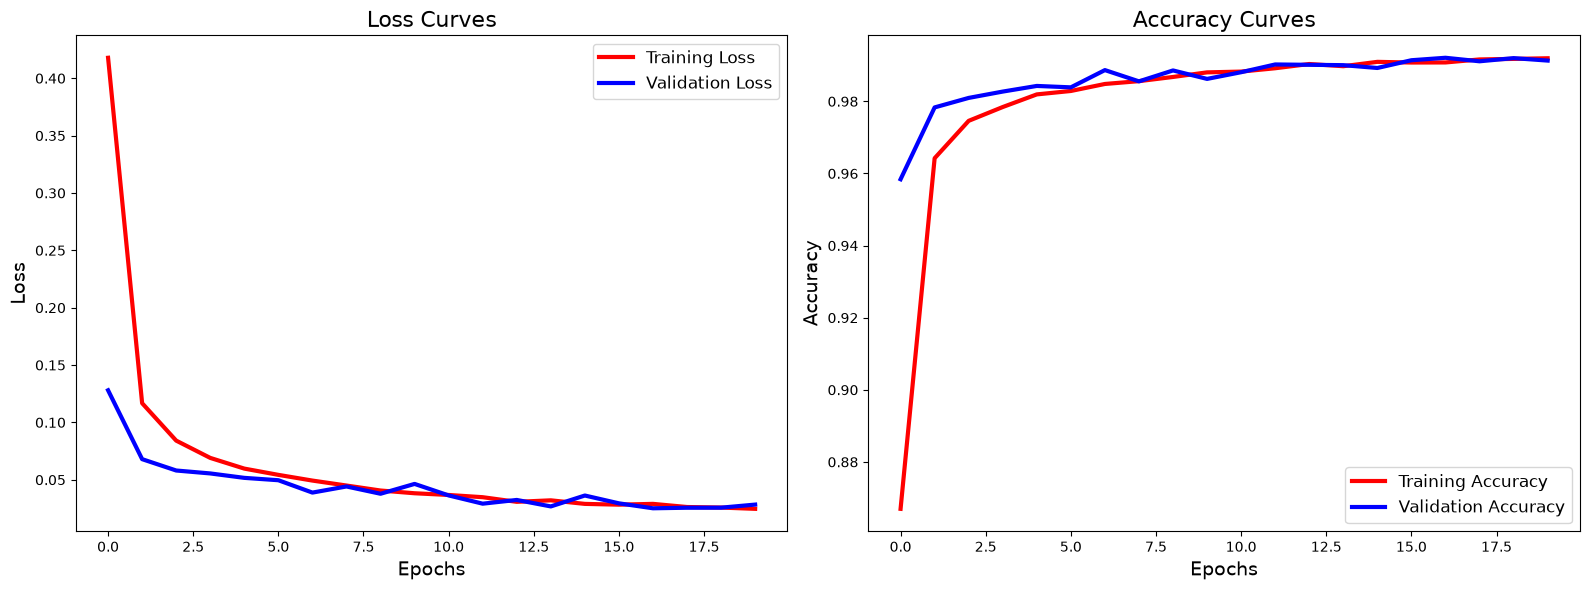

In [98]:
# Kurven Anzeigen
fig, axes = plt.subplots(1, 2, figsize=(16,6))

axes[0].plot(history['loss'], 'r', linewidth=3.0)
axes[0].plot(history['loss_val'], 'b', linewidth=3.0)
axes[0].set_title('Loss Curves', fontsize=16)
axes[0].set_xlabel('Epochs', fontsize=14)
axes[0].set_ylabel('Loss', fontsize=14)
axes[0].legend(['Training Loss', 'Validation Loss'], fontsize=12)

axes[1].plot(history['accuracy'], 'r', linewidth=3.0)
axes[1].plot(history['accuracy_val'], 'b', linewidth=3.0)
axes[1].set_title('Accuracy Curves', fontsize=16)
axes[1].set_xlabel('Epochs', fontsize=14)
axes[1].set_ylabel('Accuracy', fontsize=14)
axes[1].legend(['Training Accuracy', 'Validation Accuracy'], fontsize=12)

plt.tight_layout()
plt.show()

<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #3498; 
    border-radius: 4px;
">
  📌 <b>Aufgabe 1.5:</b><br>
  • Probieren Sie Ihr Modell aus und verändern Sie ggfs. die Layer, um bessere Ergebnisse zu erzielen.
</div>
<div style="
    padding: 12px; 
    border-left: 5px solid #e8f4fc; 
    background-color: #66611F; 
    border-radius: 4px; 
    margin-top: 5px;
">
💡 <i><b>Hinweis:</b></i> Ihr Netzwerk muss nicht perfekt sein.
</div>

In [99]:
if MODE == Mode.TEST:
    if not os.path.exists(MODEL_SAVE_PATH):
        print(f"FEHLER: Das Modell '{MODEL_SAVE_PATH}' existiert nicht.")
        exit(1)
        
    # Modell laden
    model.load_state_dict(torch.load(MODEL_SAVE_PATH, weights_only=True))

In [126]:
model.eval()
with torch.no_grad():
    draw_widget = DrawWidget(WIN_NAME, (28, 28), 20, 0.75)

    # Start-Prediction
    prediction = -1

    while True:
        # Bild holen
        image = draw_widget.get_display_image()
        image = (np.clip(image,0,1)*255).astype(np.uint8)
        image = cv2.cvtColor(image.reshape(*image.shape, 1), cv2.COLOR_GRAY2RGB)


        # Predicte, falls sich das Bild verändert hat
        if draw_widget.get_updated_state():
            img = (draw_widget.get_internal_image()-0.1307)/0.3081
            prediction = model(torch.from_numpy(draw_widget.get_internal_image()).to(dtype=torch.float32, device=device).reshape(1,1,28,28)).argmax()

        # Schreibe Prediction auf Bild
        cv2.putText(image, f"Pred: {prediction}", (50, image.shape[1]-50), cv2.FONT_HERSHEY_COMPLEX, 1.5, (0, 0, 255), 3)
        
        # Anzeigen
        cv2.imshow(WIN_NAME, image)

        # Programm schließen
        key = cv2.waitKey(1)
        if key == 27 or cv2.getWindowProperty(WIN_NAME, cv2.WND_PROP_VISIBLE) <1:  # ESC oder 'x'
            cv2.destroyAllWindows()
            break